# LegalSathi AI — RAG Pipeline Walkthrough

This notebook walks through **every stage** of the Retrieval-Augmented Generation (RAG) pipeline used by the
backend, using the **same code** (`Backend/*.py`) so what you review here is exactly what the API runs.

```
 PDFs (text, scanned pages, tables, diagrams)
   │  document_processor.py
   ▼
 Elements ── text │ ocr (scanned) │ table (markdown) │ image (OCR / vision description)
   │  chunker.py
   ▼
 Chunks (~1200 chars, 200 overlap, + metadata: file, title, page, type)
   │  ingest.py + vector_store.py  (bge-small-en-v1.5 embeddings, ONNX, CPU → upsert)
   ▼
 Pinecone (cosine, serverless)  +  BM25 keyword index
   │
 Question ─► LLM query planner (standalone question + 3 keyword search queries)
   │          + glossary expansion (abbreviations / everyday phrases → legal terms)
   │
   ▼  for each query: dense (Pinecone) + BM25  ─► RRF fusion ─► 30 candidates
   │  cross-encoder relevance score per candidate
   │  context = top 8 by fused rank + top 4 by cross-encoder (max 4 per document)
   │
   ├─ GATE 1: best relevance < threshold ───────────────► "Not in knowledge base" (no answer generated)
   ▼
 Azure OpenAI (gpt-5.4-nano) — answer ONLY from numbered passages, JSON output
   ├─ GATE 2: model says not answerable / out of scope ─► "Not in knowledge base"
   ├─ GATE 3: no valid [n] citations ───────────────────► "Not in knowledge base"
   ▼
 Answer + citations (document, page, type)
```

| File | Responsibility |
|---|---|
| `config.py` | All settings & thresholds |
| `document_processor.py` | PDF → elements (native text, OCR, tables, images) |
| `chunker.py` | Elements → chunks with metadata |
| `vector_store.py` | Embeddings, Pinecone, BM25, multi-query RRF, cross-encoder scoring |
| `rag_pipeline.py` | Query planning, glossary expansion, gates, prompt, generation, citations |
| `doc_titles.json` | Human-readable document titles used in citations |
| `ingest.py` | CLI to build the knowledge base |
| `main.py` | FastAPI server (`/api/chat`, `/api/health`, `/api/documents`) |

> Run this notebook with the **myenv** kernel. Steps 7+ need `PINECONE_API_KEY` and Azure OpenAI settings in `.env`, and `python ingest.py` (in `Backend/`) run first.

In [1]:
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# works whether the kernel starts in Notebook/, the repo root, or Backend/ (re-runs included)
BACKEND = next(p / "Backend" for p in [Path.cwd(), *Path.cwd().parents] if (p / "Backend" / "config.py").exists())
sys.path.insert(0, str(BACKEND))
os.chdir(BACKEND)

import config
print("Dataset dir     :", config.DATASET_DIR)
print("Pinecone index  :", config.PINECONE_INDEX, "/ namespace:", config.PINECONE_NAMESPACE)
print("Pinecone key set:", bool(config.PINECONE_API_KEY))
print("Embedding model :", config.EMBEDDING_MODEL)
print("Reranker model  :", config.RERANKER_MODEL)
print("LLM deployment  :", config.AZURE_OPENAI_DEPLOYMENT)
print("Tesseract       :", config.TESSERACT_CMD)
print("Chunk size/overlap:", config.CHUNK_SIZE, "/", config.CHUNK_OVERLAP)
print("Relevance gate  :", config.MIN_RELEVANCE_SCORE)

Dataset dir     : D:\LegalSathi AI\Datasets LAW
Pinecone index  : legal-docs / namespace: default
Pinecone key set: True
Embedding model : BAAI/bge-small-en-v1.5
Reranker model  : Xenova/ms-marco-MiniLM-L-6-v2
LLM deployment  : gpt-5.4-nano
Tesseract       : C:\Program Files\Tesseract-OCR\tesseract.exe
Chunk size/overlap: 1200 / 200
Relevance gate  : 0.1


## Step 1 — Inspect the dataset

For each PDF we count pages, how many pages have **no text layer** (scanned → need OCR), and embedded images.

In [2]:
import pymupdf
from document_processor import open_pdf

rows = []
for pdf in sorted(config.DATASET_DIR.glob("*.pdf")):
    doc = open_pdf(pdf)
    scanned = sum(1 for p in doc if len(p.get_text().strip()) < config.MIN_TEXT_CHARS)
    images = sum(len(p.get_images()) for p in doc)
    rows.append((pdf.name[:60], len(doc), scanned, images))
    doc.close()

print(f"{'file':62}{'pages':>7}{'scanned':>9}{'images':>8}")
for r in rows:
    print(f"{r[0]:62}{r[1]:>7}{r[2]:>9}{r[3]:>8}")
print(f"\nTotal: {len(rows)} PDFs, {sum(r[1] for r in rows)} pages, {sum(r[2] for r in rows)} low-text pages")

file                                                            pages  scanned  images
17773_2023_8_1501_67799_Judgement_27-Jan-2026.pdf                  42        0       2
202504081796627129.pdf                                             19        0       0
202509251385425867.pdf                                              3        0       0
2033_2015_11_1502_19663_Judgement_15-Jan-2020.pdf                  42        0       0
31_Labour_Law-I.pdf                                                91       91      91
40060_2019_5_1501_71696_Judgement_01-Jun-2026.pdf                  54        0       1
40659.pdf                                                          12        0       0
83978455025732b99b0165def80ab171.pdf                               38        4       0
c9fe9c9b6840524844316f74bb1c556c.pdf                              402        0       1
Code_on_Social_Security_2020.pdf                                  113        0       1
Code_on_Wages_2019.pdf                     

## Step 2 — Scanned pages → OCR

`31_Labour_Law-I.pdf` is fully scanned (no text layer). The page is rendered at 300 DPI and passed to Tesseract.
With `--vision` the page image is sent to the Azure vision model instead, which also rebuilds tables as Markdown.

Native text layer length: 0


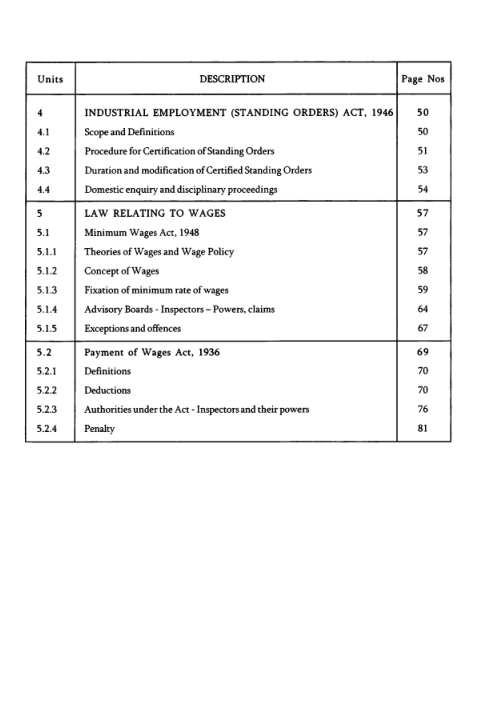

OCR (ocr) -> 552 chars

INDUSTRIAL EMPLOYMENT (STANDING ORDERS) ACT, 1946

Scope and Definitions

Procedure for Certification of Standing Orders

Duration and modification of Certified Standing Orders

Domestic enquiry and disciplinary proceedings

LAW RELATING TO WAGES

Minimum Wages Act, 1948

Theories of Wages and Wage Policy

Concept of Wages

Fixation of minimum rate of wages

Advisory Boards - Inspectors ~ Powers, claims

Exceptions and offences

Payment of Wages Act, 1936

Definitions

Deductions

Authorities under the Act - Inspectors and their powers

Penalty




In [3]:
from document_processor import extract_scanned_page, pixmap_to_pil

doc = open_pdf(config.DATASET_DIR / "31_Labour_Law-I.pdf")
page = doc[4]
print("Native text layer length:", len(page.get_text().strip()))

preview = pixmap_to_pil(page.get_pixmap(dpi=60))
display(preview)

etype, text = extract_scanned_page(page, use_vision=False)
print(f"OCR ({etype}) -> {len(text)} chars\n")
print(text[:1200])

## Step 3 — Tables → Markdown

On digital pages PyMuPDF's table finder detects ruled/aligned tables. Each table is stored as a **separate
`table` element** in Markdown so rows and columns stay aligned for the LLM.

In [4]:
from document_processor import extract_tables

doc = open_pdf(config.DATASET_DIR / "Guide-to-the-Labour-Codes.pdf")
for md_table in extract_tables(doc[19]):   # page 20
    print(md_table[:1500])

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
|Chapter|Applicability|
|---|---|
|Provident fund|Every establishment in which 20 or more employees are employed (_regardless of salaries earned by each employee_).|
|Employees State Insurance|Every establishment in which 10 or more employees are employed (_regardless of salaries earned by each employee_). However, establishments carrying on hazardous or life&#45;threatening occupations, as notified by the Central Government, with even 1 employee will be covered.|
|Gratuity|• Every factory, mine, oilfield, plantation, port and railway company; • Every shops or establishment in which 10 or more employees are employed or were employed on any day in the last 12 months; and • Such shops and establishments as may be notified by the appropriate Government.|
|Maternity benefits|• Every factory, mine or plantation, including any such establishment belonging to the Government; and • Every shops or establishme

## Step 4 — Images & diagrams

Embedded images that are big enough (≥ 250 px and ≥ 8 % of the page) are OCR'd so text inside diagrams,
infographics and inserted scans becomes searchable. Logos/icons are skipped. With `--vision`, the model writes a
plain-language description of flowcharts/diagrams and returns `DECORATIVE` for photos, which are dropped.

In [5]:
from document_processor import extract_images

doc = open_pdf(config.DATASET_DIR / "Guide-to-the-Labour-Codes.pdf")
seen = set()
for pno in range(len(doc)):
    texts = extract_images(doc, doc[pno], seen, use_vision=False)
    for t in texts:
        print(f"--- page {pno + 1} image text ---")
        print(t[:500], "\n")

--- page 1 image text ---
The New Labour Codes:

A Guide to
What you need to know 

--- page 6 image text ---
Ee
a=

Wage Code

Private sector establishments will likely
fall under the purview of the respective
State Government where their
establishments are located, except
establishments of specified industries
(railways, mines, oil fields, major ports, air
transport service, telecommunication,
banking and insurance companies) which
will be under the Central Government.

SS Code

¢ Private sector establishments with
establishments in more than 1 State
will fall under the purview of the
Central Governme 

--- page 7 image text ---
Cie

Facilitatorcum-inspector

Decriminalization

aly
See
tee Rat
ei nee
Higher monetary Compounding Opportunity
penalties of offences to rectify

tH
Limitation period
for filing claims,
initiating
proceedings

fil

Bar on jurisdiction
of civil courts 

--- page 17 image text ---
Working Hours

8-hour upper limit on daily
working hours.

the period of work ea

## Step 5 — Full extraction + chunking for one document

`process_pdf` combines the steps above per page. `chunk_elements` splits each element recursively
(paragraph → line → sentence → word) into ~1200-char chunks with 200-char overlap. Large tables are split by rows
with the header repeated. Before embedding, each chunk is prefixed with its document title, type and page
(`embedding_text`) so that a chunk like "The limit is 20 employees" keeps its context.

In [6]:
from collections import Counter
from document_processor import process_pdf
from chunker import chunk_elements, embedding_text

elements = process_pdf(config.DATASET_DIR / "Guide-to-the-Labour-Codes.pdf")
chunks = chunk_elements(elements)
print("Elements by type:", Counter(e["type"] for e in elements))
print("Chunks by type  :", Counter(c["metadata"]["type"] for c in chunks))
print("Chunk length    : min", min(len(c["text"]) for c in chunks), "max", max(len(c["text"]) for c in chunks))
print("\nExample chunk id:", chunks[10]["id"])
print(embedding_text(chunks[10])[:700])

Elements by type: Counter({'text': 25, 'image': 3, 'ocr': 2, 'table': 1})
Chunks by type  : Counter({'text': 84, 'image': 6, 'ocr': 3, 'table': 1})
Chunk length    : min 54 max 1530

Example chunk id: e2333cb3b6f42fc2-p5-text-0
Document: A Guide to the New Labour Codes | Text | Page 5
A Guide to The New Labour Codes:
What you need to know

• ‘Worker’, a subset of ‘employee’, is defined similar to the term ‘workman’ under the Industrial
Disputes Act, 1947 ("IDA"). However, it now specifically excludes apprentices and includes sales
promotion employees and working journalists, and has also increased the salary threshold for
exemption of supervisors to INR 18,000 per month (from INR 10,000).

Key Impact: A larger workforce is now accorded protection under various provisions of the Labour
Codes which were previously not available to them.


## Step 6 — Embeddings

`BAAI/bge-small-en-v1.5` (384-dim) runs locally via ONNX (`fastembed`) — no GPU and no text leaves the machine for
embedding (only the vectors + chunk metadata are stored in Pinecone). Queries get the bge instruction prefix; passages don't. Below: cosine similarity between a question and
a relevant vs. irrelevant passage.

In [7]:
import numpy as np
from vector_store import embed_query, embed_passages

q = embed_query("How many employees make EPF applicable to an establishment?")
p_rel, p_irr = embed_passages([
    "Provident fund applies to every establishment in which 20 or more employees are employed.",
    "The recipe needs two cups of flour and one egg.",
])
cos = lambda a, b: float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))
print("dim:", len(q))
print("relevant  :", round(cos(q, p_rel), 3))
print("irrelevant:", round(cos(q, p_irr), 3))

dim: 384
relevant  : 0.664
irrelevant: 0.449


## Step 6b — Store embeddings in Pinecone (ingestion)

This is what `python ingest.py` does. Every chunk is embedded locally (bge-small, 384-dim) and **upserted** to the
Pinecone index together with its text and citation metadata (`doc_id`, `source`, `title`, `page`, `type`).
Chunk ids are deterministic (`<file sha256>-p<page>-<type>-<n>`), so re-running overwrites instead of duplicating.

First we store the one document chunked in Step 5 and read a vector back to prove it is in Pinecone.

In [8]:
from vector_store import get_collection

store = get_collection()           # connects; creates the index if it does not exist
print("Index:", config.PINECONE_INDEX, "| namespace:", config.PINECONE_NAMESPACE)
print("Vectors before:", store.count())

BATCH = 256
for i in range(0, len(chunks), BATCH):   # `chunks` from Step 5 (Guide-to-the-Labour-Codes.pdf)
    batch = chunks[i:i + BATCH]
    store.upsert(
        ids=[c["id"] for c in batch],
        documents=[c["text"] for c in batch],
        metadatas=[c["metadata"] for c in batch],
        embeddings=embed_passages([embedding_text(c) for c in batch]),
    )
print(f"Upserted {len(chunks)} chunks")

# read one back (Pinecone stats are eventually consistent, fetch is immediate)
v = store.index.fetch(ids=[chunks[10]["id"]], namespace=store.ns).vectors[chunks[10]["id"]]
print("Fetched:", v.id, "| dim:", len(v.values), "| meta:", {k: v.metadata[k] for k in ("title", "page", "type")})

Index: legal-docs | namespace: default
Vectors before: 4347
Upserted 94 chunks
Fetched: e2333cb3b6f42fc2-p5-text-0 | dim: 384 | meta: {'title': 'A Guide to the New Labour Codes', 'page': 5, 'type': 'text'}


Now index the **whole dataset**. This is incremental: files already in Pinecone (same sha256) are skipped, so
re-running the notebook is cheap. The first full run OCRs ~170 scanned pages and embeds ~18k chunks — expect a long run.
Extracted text is cached in `Backend/data/extracted/`, so a later rebuild only re-embeds.

Set `RESET = True` to delete and rebuild the index, `INGEST_ALL = False` to skip this cell.

In [9]:
import ingest

INGEST_ALL = True
RESET = False

if INGEST_ALL:
    ingest.ingest(reset=RESET)
print("Vectors in Pinecone:", get_collection().count())

[1/159] 17773_2023_8_1501_67799_Judgement_27-Jan-2026.pdf: already indexed
[2/159] 202504081796627129.pdf: already indexed
[3/159] 202509251385425867.pdf: already indexed
[4/159] 2033_2015_11_1502_19663_Judgement_15-Jan-2020.pdf: already indexed
[5/159] 31_Labour_Law-I.pdf: already indexed
[6/159] 40060_2019_5_1501_71696_Judgement_01-Jun-2026.pdf: already indexed
[7/159] 40659.pdf: already indexed
[8/159] 83978455025732b99b0165def80ab171.pdf: already indexed
[9/159] c9fe9c9b6840524844316f74bb1c556c.pdf: already indexed
[10/159] Code_on_Social_Security_2020.pdf: already indexed
[11/159] Code_on_Wages_2019.pdf: already indexed
[12/159] Companies_Act_2013_AI_reconstruction.md: already indexed
[13/159] companiesact2013.pdf: already indexed
[14/159] Competition_Act_2002.pdf: 242 chunks {'text': 65} in 40s
[15/159] Competition_Amendment_Act_2023.pdf: 86 chunks {'text': 21} in 19s
[16/159] Complaint handling guidelines (1).pdf: 11 chunks {'ocr': 4} in 13s
[17/159] Core_4.pdf: 348 chunks {'tex

KeyboardInterrupt: 

## Step 7 — Query planning (LLM)

Users ask vaguely ("explain retrenchment compensation"); the statute text that answers it uses different words
("fifteen days' average pay for every completed year of continuous service", "Section 25F").
One LLM call rewrites follow-ups into a standalone question **and** writes 3 keyword-rich search queries.
The pipeline then adds one more query from `data/glossary.json` (e.g. *ESI* → *Employees' State Insurance*), which works even if the LLM planner fails.

In [ ]:
import rag_pipeline
from vector_store import HybridRetriever

retriever = rag_pipeline.get_retriever(refresh=True)   # reload after Step 6b
print("Chunks in Pinecone:", retriever.size)

question = "Explain retrenchment compensation under the Industrial Disputes Act."
standalone, queries = rag_pipeline.plan_queries(question, [])
print("Standalone:", standalone)
if extra := rag_pipeline.glossary_query(standalone):   # same as answer_question()
    queries = [*queries, extra]
for q in queries: print("  search query:", q)

## Step 8 — Hybrid retrieval: Pinecone (dense) + BM25 (keyword), fused with RRF

Dense search finds paraphrases; BM25 nails exact legal terms ("Section 25F", "NCLT", "gratuity").
Both run for the question **and** each search query; all ranked lists are merged with
**Reciprocal Rank Fusion**: `score(d) = Σ 1 / (60 + rank_in_list)`.

In [ ]:
import re

def show(cid):
    m = retriever.metas[retriever.index[cid]]
    return f"{m['title'][:40]:40} p{m['page'] or '-':<4} {m['type']}"

dense = retriever.dense_search(question)
sparse = retriever.bm25_search(question)
print("Top 5 dense (cosine sim) for the raw question:")
for cid, s in dense[:5]: print(f"  {s:.3f}  {show(cid)}")
print("\nTop 5 BM25 for the raw question:")
for cid, s in sparse[:5]: print(f"  {s:6.2f}  {show(cid)}")

lists = []
for q in [standalone] + queries:
    lists += [retriever.dense_search(q), retriever.bm25_search(q)]
fused = retriever.rrf(*lists)
print(f"\nTop 10 after multi-query RRF ({len(lists)} ranked lists):")
answer_re = re.compile(r"(fifteen|15) days'? average pay", re.I)
for cid in fused[:10]:
    mark = "  <-- contains '15 days average pay'" if answer_re.search(retriever.docs[retriever.index[cid]]) else ""
    print("   ", show(cid), mark)

## Step 9 — Cross-encoder scoring & context selection

`ms-marco-MiniLM-L-6-v2` reads question + chunk **together** and outputs a relevance logit (sigmoid → 0..1).

*Design decision (measured on this corpus):* reordering purely by the cross-encoder pushed precise statutory
chunks (e.g. "15 days' average pay") **down** to rank 40+, because they don't repeat the question's words.
So the context = **top 8 by fused rank + top 4 by cross-encoder score**, max 4 chunks per document
(so one long file can't crowd out the Act that has the answer). The cross-encoder's best score powers **Gate 1**.

In [ ]:
top = retriever.retrieve(standalone, queries)
print("fused_rank  relevance  chunk")
for c in top:
    m = c["metadata"]
    print(f"{c['fused_rank']:>10}  {c['score']:9.3f}  {m['title'][:35]:35} p{m['page'] or '-':<4} | {c['text'][:70]!r}")

## Step 10 — Gate 1: relevance threshold (calibration)

If the best candidate scores below `MIN_RELEVANCE_SCORE`, we reply *"not found in knowledge base"*
**without generating an answer** — no chance to hallucinate. In-domain questions score ~0.6–1.0, off-topic ~0.00.

In [ ]:
probe = [
    ("in",  "When is gratuity payable to an employee?"),
    ("in",  "What are the powers of the National Company Law Tribunal?"),
    ("in",  "What is the definition of a private company under the Companies Act 2013?"),
    ("in",  "What is the applicability of ESI?"),
    ("out", "Who won the 2011 cricket world cup?"),
    ("out", "How do I bake a chocolate cake?"),
    ("out", "Write a Python function to sort a list"),
    ("out", "What is the capital of Australia?"),
]
for kind, q in probe:
    best = max((c["score"] for c in retriever.retrieve(q)), default=0.0)   # no chunks -> refuse, like Gate 1
    flag = "PASS" if best >= config.MIN_RELEVANCE_SCORE else "REFUSE"
    print(f"{kind:4} {best:.3f}  {flag:6}  {q}")
print("\nThreshold:", config.MIN_RELEVANCE_SCORE)

## Step 11 — Prompt construction

Passages are numbered `[1]..[n]` with document, file, page and type. The system prompt forbids outside knowledge
and forces a JSON reply with `in_scope`, `answerable`, `answer`, `used_passages`.

In [ ]:
import rag_pipeline
print(rag_pipeline.SYSTEM_PROMPT)
print("\n================ CONTEXT (truncated) ================\n")
print(rag_pipeline.format_context(top)[:2000])

You are LegalSathi AI, an assistant for Indian LABOUR LAW and CORPORATE / COMPANY / BUSINESS LAW.

STRICT RULES
1. Answer ONLY using the numbered CONTEXT passages provided. Never use outside knowledge,
   never guess, never fill gaps with general legal knowledge.
2. If the passages contain information that addresses the question - fully or partly - set
   "answerable" to true, answer with what the passages say and briefly state what they do not cover.
   Set "answerable" to false only when no passage addresses the question.
3. If the question is not about law (e.g. cooking, sports, coding, general chit-chat), set
   "in_scope" to false.
4. Cite every factual statement with passage numbers in square brackets, e.g. [1] or [2][4].
5. Quote section numbers, act names, amounts and time limits exactly as they appear in the passages.
6. Be clear and structured: short paragraphs or bullet points; Markdown tables when comparing.
7. This is legal information, not legal advice.

Respond with a JS

## Step 12 — End-to-end answers (all gates)

* A covered question → grounded answer with citations.
* An off-topic question → refused at Gate 1 or Gate 2.
* A legal question the documents don't cover → refused by Gate 2 (model self-check).

In [ ]:
from IPython.display import Markdown

def run(q, history=None):
    r = rag_pipeline.answer_question(q, history)
    print(f"Q: {q}\nanswered={r['answered']}  reason={r['reason']}  top_scores={r.get('debug_top_scores')}")
    display(Markdown(r["answer"]))
    for c in r["citations"]:
        print(f"   [{c['n']}] {c['title']} ({c['source']}) p{c['page']} [{c['type']}]")
    print("-" * 100)
    return r

r1 = run("When is gratuity payable to an employee?")
r2 = run("How do I bake a chocolate cake?")
r3 = run("What is the corporate tax rate in Singapore for 2026?")

Q: When is gratuity payable to an employee?
answered=True  reason=grounded  top_scores=[0.998, 0.99, 0.942, 0.998, 0.941, 0.963, 0.836, 0.02, 0.991]
   [1] Labour Laws (DCOM207) (DCOM207_LABOUR_LAWS.pdf) p244 [text]
   [4] Labour Laws in India (Labour Act (1).pdf) p88 [text]
----------------------------------------------------------------------------------------------------
Q: How do I bake a chocolate cake?
answered=False  reason=low_relevance  top_scores=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
----------------------------------------------------------------------------------------------------
Q: What is the corporate tax rate in Singapore for 2026?
answered=False  reason=low_relevance  top_scores=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
----------------------------------------------------------------------------------------------------


Gratuity is payable to an employee on termination of employment after the employee has rendered continuous service for not less than 5 years—on the employee’s superannuation, or on retirement or resignation, or on death or disablement due to accident or disease. [1][4]

Also, the requirement of completing 5 years of continuous service is not necessary if termination of employment is due to death or disablement. In case of death, gratuity is payable to the nominee or to the guardian of such nominee. [1]

I could not find an answer to this question in my knowledge base of labour law and corporate law documents, so I won't guess. Try rephrasing, or ask about a topic covered in the documents.

I could not find an answer to this question in my knowledge base of labour law and corporate law documents, so I won't guess. Try rephrasing, or ask about a topic covered in the documents.

## Step 13 — Follow-up questions (conversation memory)

The frontend sends the last turns as `history`. Follow-ups like *"what about its time limit?"* are rewritten into a
standalone question before retrieval, so the search isn't polluted by pronouns.

In [ ]:
hist = [{"role": "user", "content": "When is gratuity payable to an employee?"},
        {"role": "assistant", "content": r1["answer"]}]
r4 = run("How is the amount calculated?", hist)
print("Standalone question used for retrieval:", r4["standalone_question"])

Q: How is the amount calculated?
answered=True  reason=grounded  top_scores=[1.0, 0.998, 1.0, 0.999, 0.992, 1.0, 0.976, 0.543, 0.982]
   [1] Labour Laws (DCOM207) (DCOM207_LABOUR_LAWS.pdf) p246 [text]
   [2] Labour Laws (DCOM207) (DCOM207_LABOUR_LAWS.pdf) p244 [text]
   [3] Labour Laws (DCOM207) (DCOM207_LABOUR_LAWS.pdf) p238 [text]
   [4] Labour Laws in India (Labour Act (1).pdf) p90 [text]
----------------------------------------------------------------------------------------------------
Standalone question used for retrieval: How is the amount of gratuity payable to an employee calculated?


The amount of gratuity is calculated as follows:

- **For every completed year of service (or part thereof) in excess of six months**, the employer pays gratuity at the rate of **“fifteen days’ wages”** based on the employee’s **“rate of wages last drawn”**. [1][2][4]

- **Monthly-rated employee:** the **fifteen days’ wages** are calculated by **dividing the monthly rate of wages last drawn by twenty-six and multiplying the quotient by fifteen**. [3][4]

- **Piece-rated employee:** **daily wages** are computed as the **average of the total wages received for a period of three months immediately preceding the termination of employment**, and **“wages paid for any overtime work shall not be taken into account.”** [2][3][4]

- **Seasonal establishment (not employed throughout the year):** gratuity is calculated at the rate of **“seven days wages for each season.”** [2][4]

- (As a formula provided in the document): **“Basic + DA (Wages Last drawn)* 15days 126 * number of years of continuous service (six months or less to be ignored and more than six months to be counted as full year)”**. [1]

**Not covered in the provided passages:** the document does not explain the full computation steps for all cases in a single unified formula beyond the above; it mainly specifies the rate basis and the method for monthly/piece-rated/seasonal employees. [1][2][3][4]

## Rebuilding / extending the knowledge base

```powershell
cd Backend
..\myenv\Scripts\activate
python ingest.py              # index new PDFs only (incremental)
python ingest.py --reset      # rebuild from scratch
python ingest.py --vision     # better scans/tables/diagrams via Azure vision (costs tokens)
```
Extracted elements are cached in `Backend/data/extracted/*.jsonl`, so a `--reset` only re-embeds.
Embeddings are upserted to the Pinecone index (`--reset` deletes and recreates it).
Then call `POST /api/reload` (or restart uvicorn).

**Tuning knobs** (`config.py`): `MIN_RELEVANCE_SCORE` (stricter/looser refusal), `FUSED_CONTEXT_N` / `RERANK_CONTEXT_N` / `MAX_CHUNKS_PER_DOC`,
`CHUNK_SIZE`/`CHUNK_OVERLAP`, `EMBEDDING_MODEL` (e.g. `BAAI/bge-base-en-v1.5` for higher quality, re-ingest required).